The concept is to investigate whether the multivariate autoregressive model can be treated as a classical ML problem to add regularization.

1. Implement classical algorithm proposed by Kamiński with OLS
2. Implement algorithm with sklearn's MultiTaskLasso (drop for now)
3. Implement encoder doing the same thing

In [1]:
import config as c
import pandas as pd
import numpy as np
import seaborn as sns
import mne
import matplotlib.pyplot as plt
from lib import *

In [2]:
fpr = load_memmap()
single_exam = fpr[1220] #randomly pick a recording

In [3]:
#sanity check
#single_exam.shape

Not setting metadata
150 matching events found
No baseline correction applied
0 projection items activated
Using matplotlib as 2D backend.


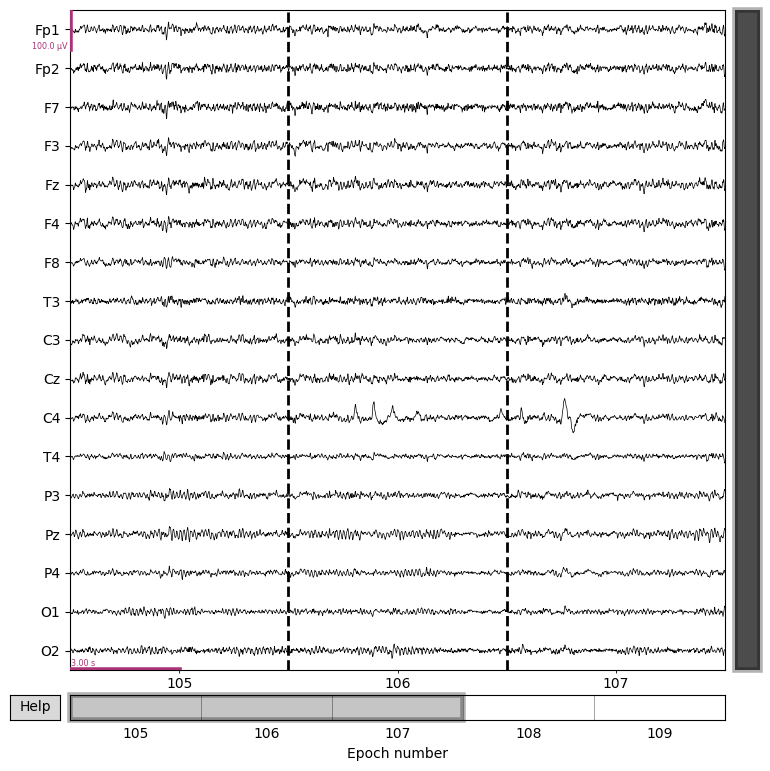

In [4]:
g = plot_epoch_eeg(single_exam, start_epoch = 105, end_epoch = 110, n_epochs_to_plot = 3)

In [5]:
one_window = single_exam[106, :, :]

Creating RawArray with float64 data, n_channels=17, n_times=768
    Range : 0 ... 767 =      0.000 ...     5.992 secs
Ready.


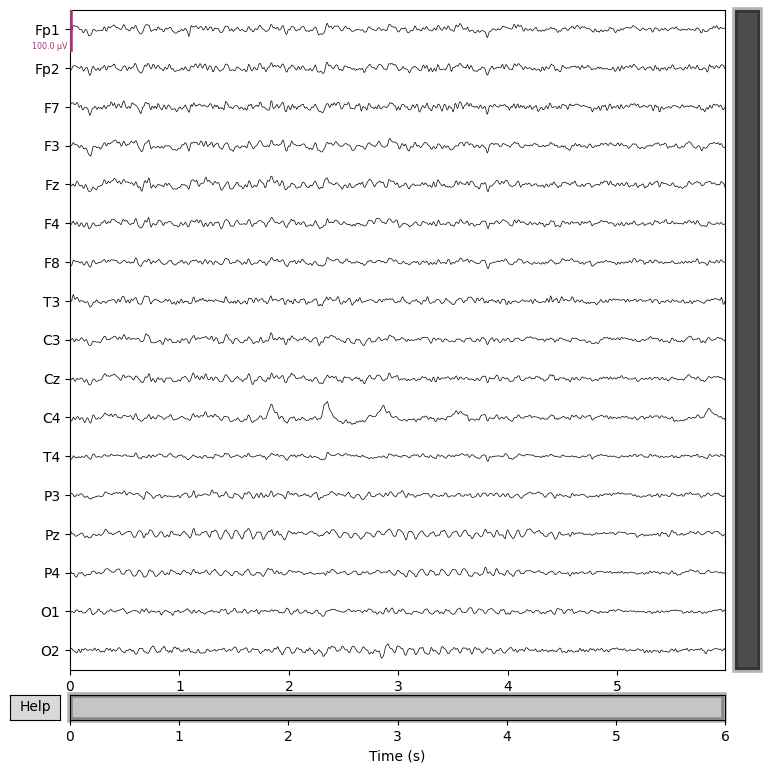

In [6]:
g = plot_one_window(one_window)

# prepare for modelling

In [7]:
one_window_zscored = zscore_per_channel(one_window)
one_window_zscored

array([[ 9.2437968e-02, -9.9402899e-01, -1.1269472e+00, ...,
         5.2540827e-01,  3.7033170e-01,  3.8362205e-01],
       [-1.0673590e+00, -1.1799066e+00, -4.6967602e-01, ...,
         4.8632911e-01, -4.1804132e-01, -2.4759974e-01],
       [ 3.3936998e-01,  1.3137319e+00,  1.7785696e+00, ...,
        -8.9218509e-01, -3.1723681e-01,  2.0274317e-01],
       ...,
       [ 9.7705799e-01,  5.7881802e-01, -4.3526566e-01, ...,
         9.8484615e-04, -5.0548720e-01, -9.4119668e-01],
       [-6.4089584e-01, -5.2301598e-01, -5.6825750e-02, ...,
         1.0399733e+00,  4.9572921e-01,  6.9397017e-02],
       [ 2.7929869e-01,  1.0398926e+00,  1.1275957e+00, ...,
         9.6501464e-01,  3.3695710e-01, -4.6856377e-01]],
      shape=(17, 768), dtype=float32)

Creating RawArray with float64 data, n_channels=17, n_times=768
    Range : 0 ... 767 =      0.000 ...     5.992 secs
Ready.


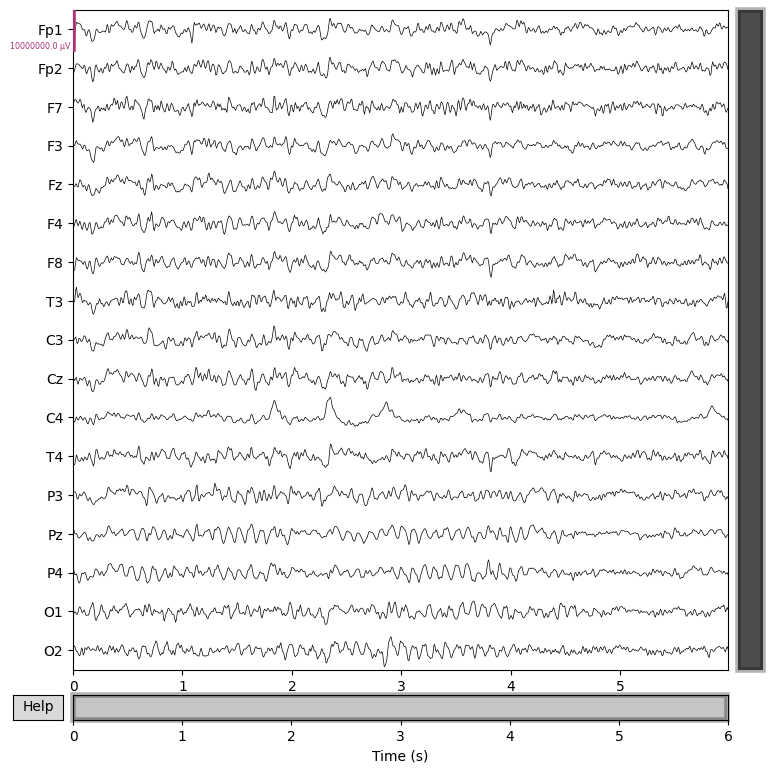

In [8]:
g = plot_one_window(one_window_zscored, scalings = dict(eeg=5))

For my application it is save to set common order to 9 (we are aiming at around 5 frequency peaks) (this is shown in another notebook by sampling the dataset to probe for PSDs and AIC criterion). Considering the set length of the epoch to 6 x 128 the unbiased version of the algorithm can be safely used (iwhat = 2).

## input: one epoch

### standard approach

In [9]:
AR, _ = AR_coeff(one_window_zscored)
mvar_H = mvar_H(AR)

### prepare band-averaged features of non-normalized DTF (magnitude) & frequency normalized DTF

In [10]:
NDTF = np.abs(mvar_H) ** 2 #not normalized
ffDTF = ffDTF(mvar_H)

## visualization for one directed information flow

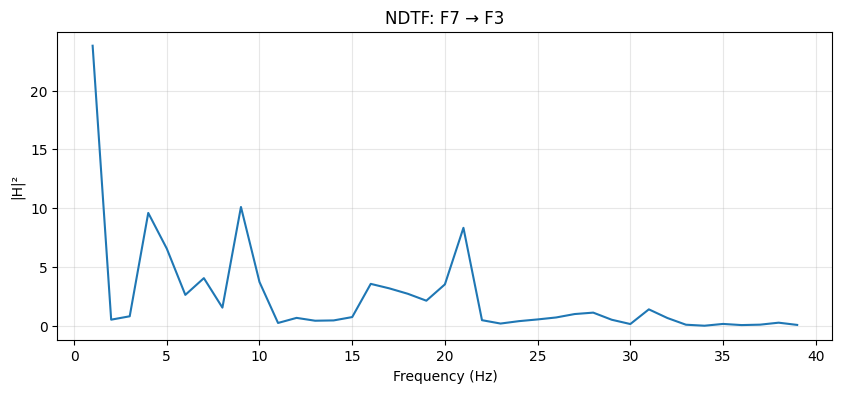

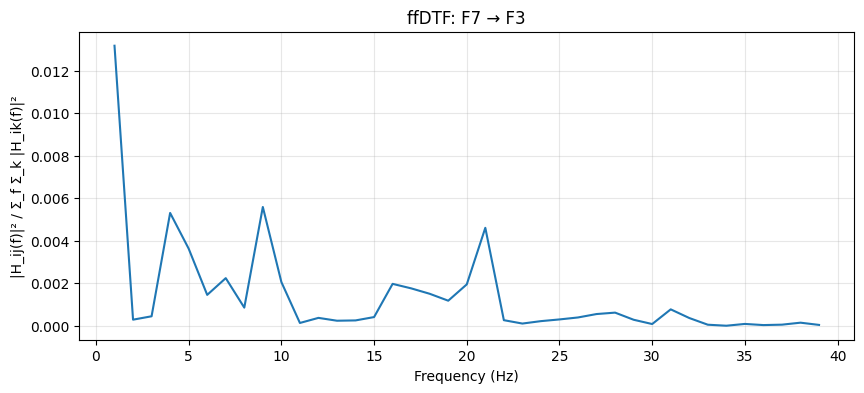

In [11]:
plot_one_flow(NDTF, 2, 3, ylabel = "|H|²", conn_name = 'NDTF')
plot_one_flow(ffDTF, 2, 3)

It looks as predicted -> very similar with other values on y axis.

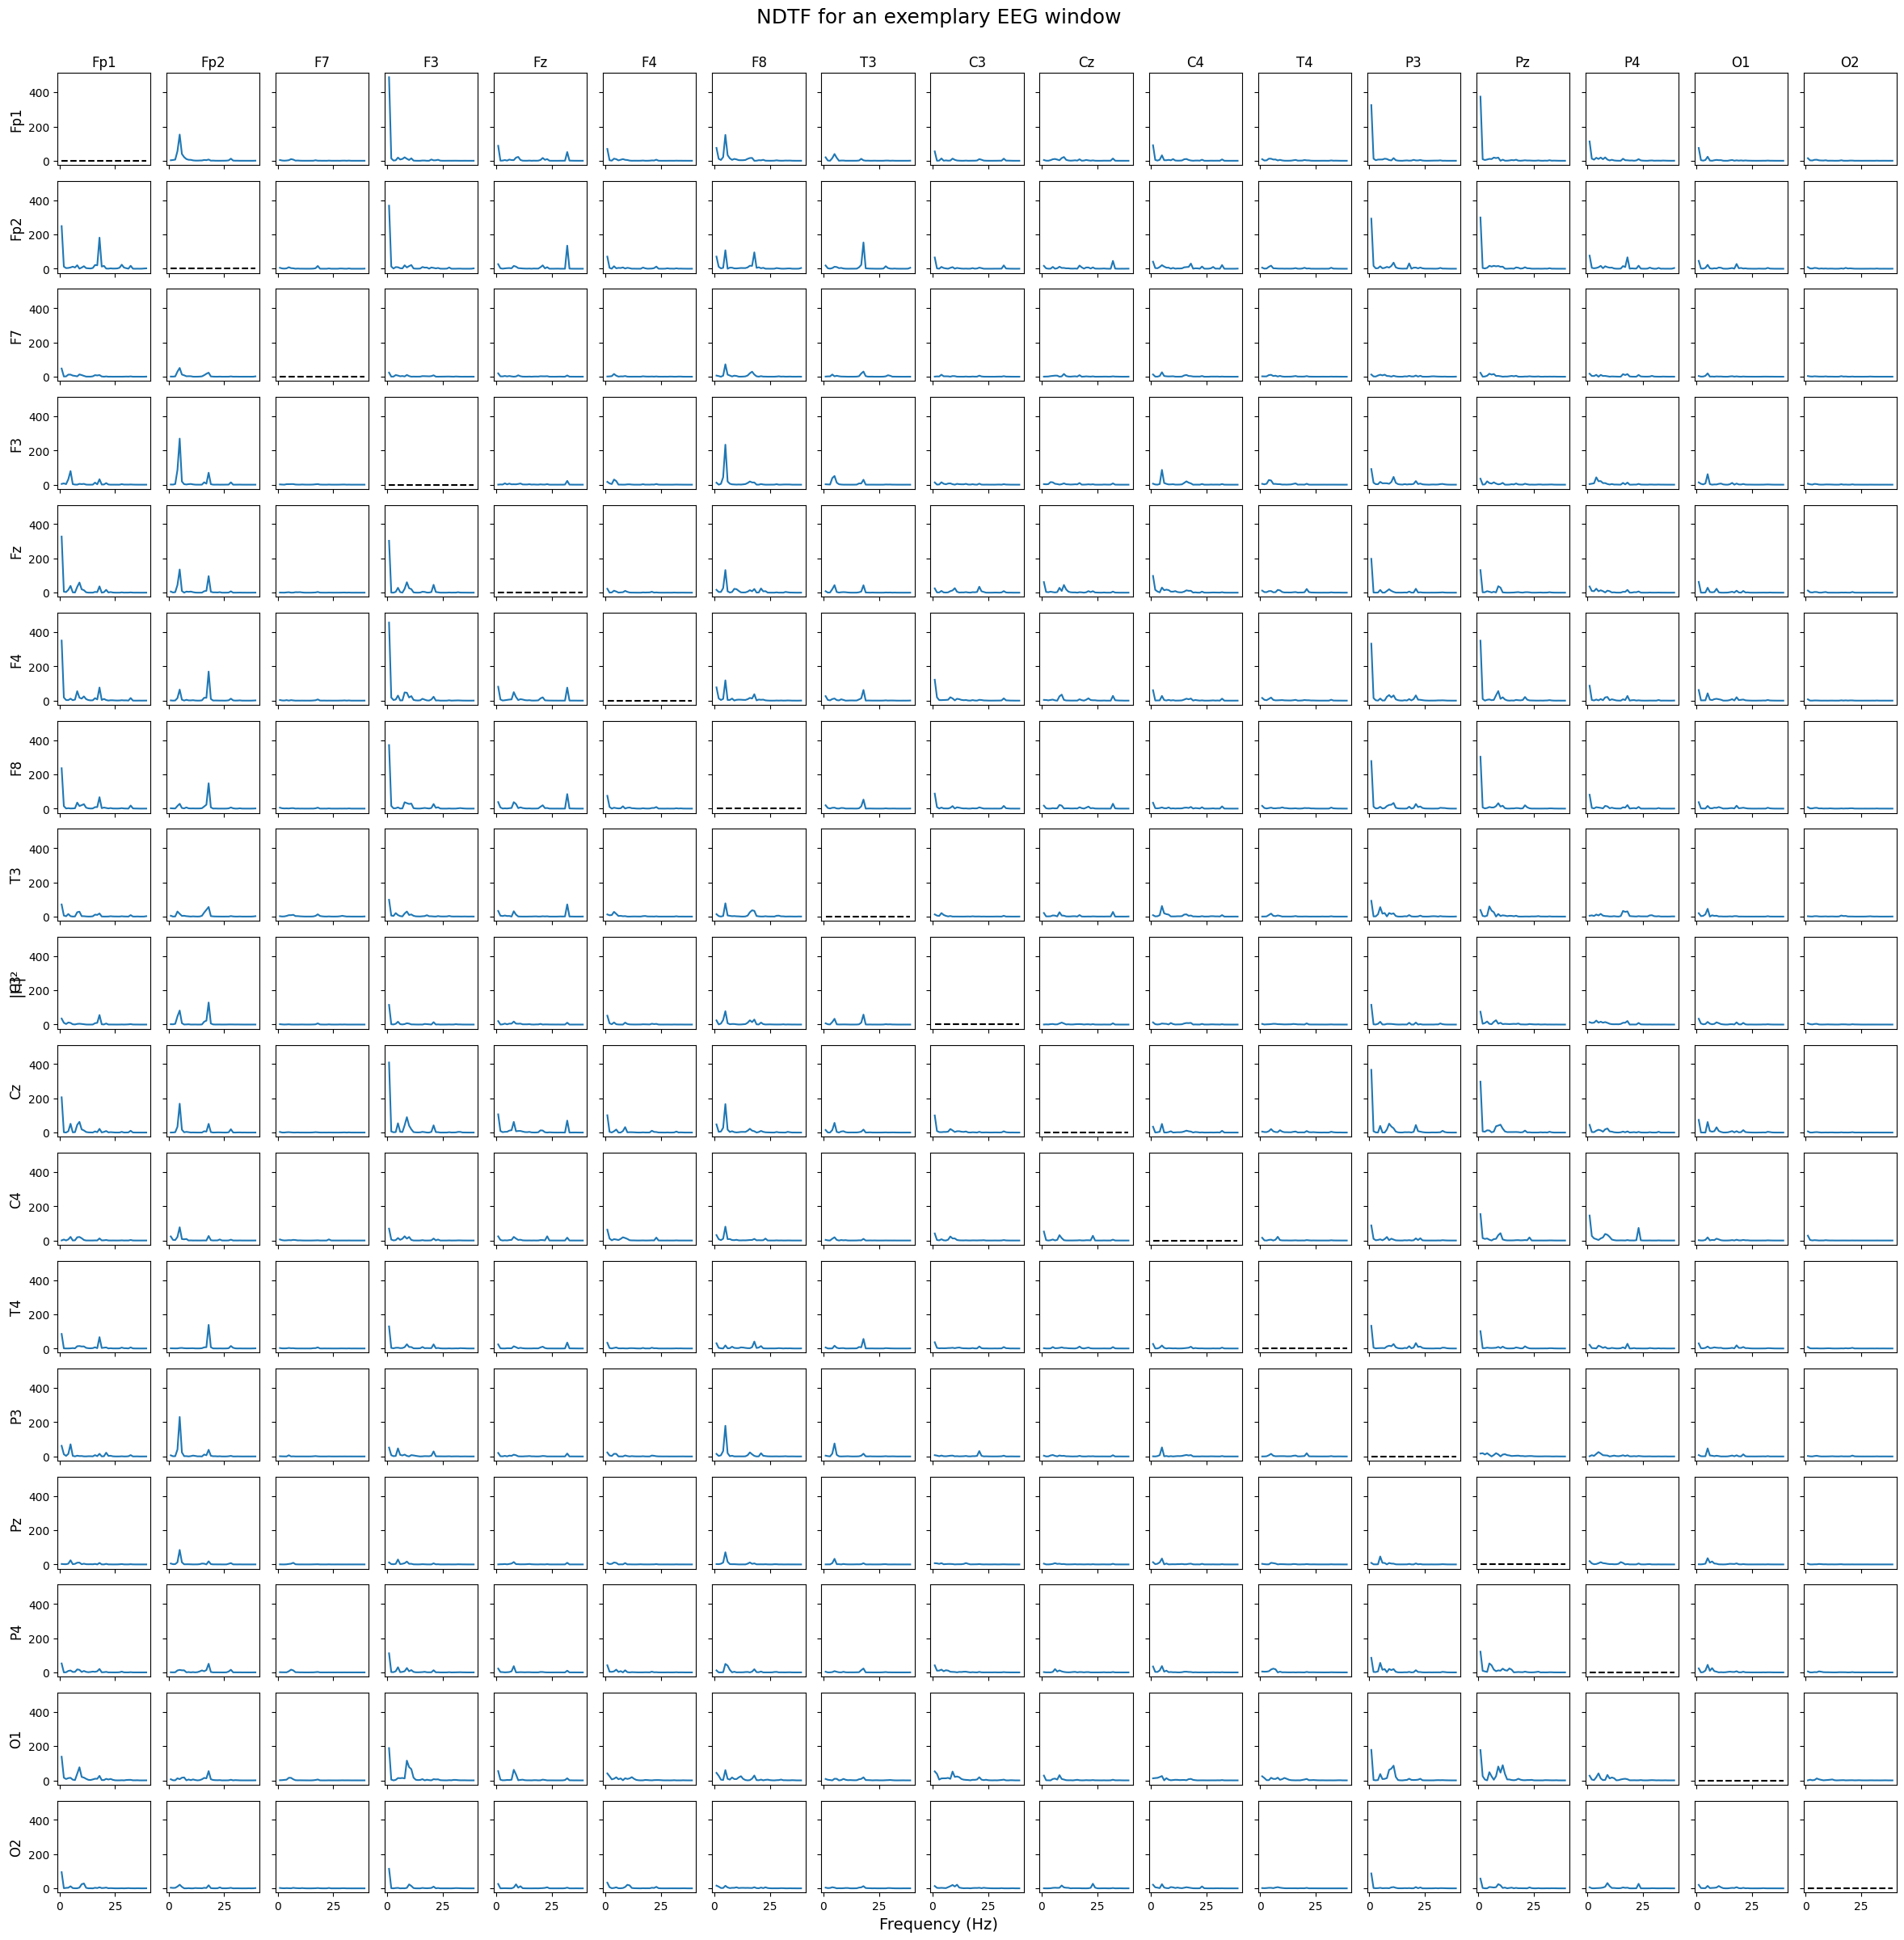

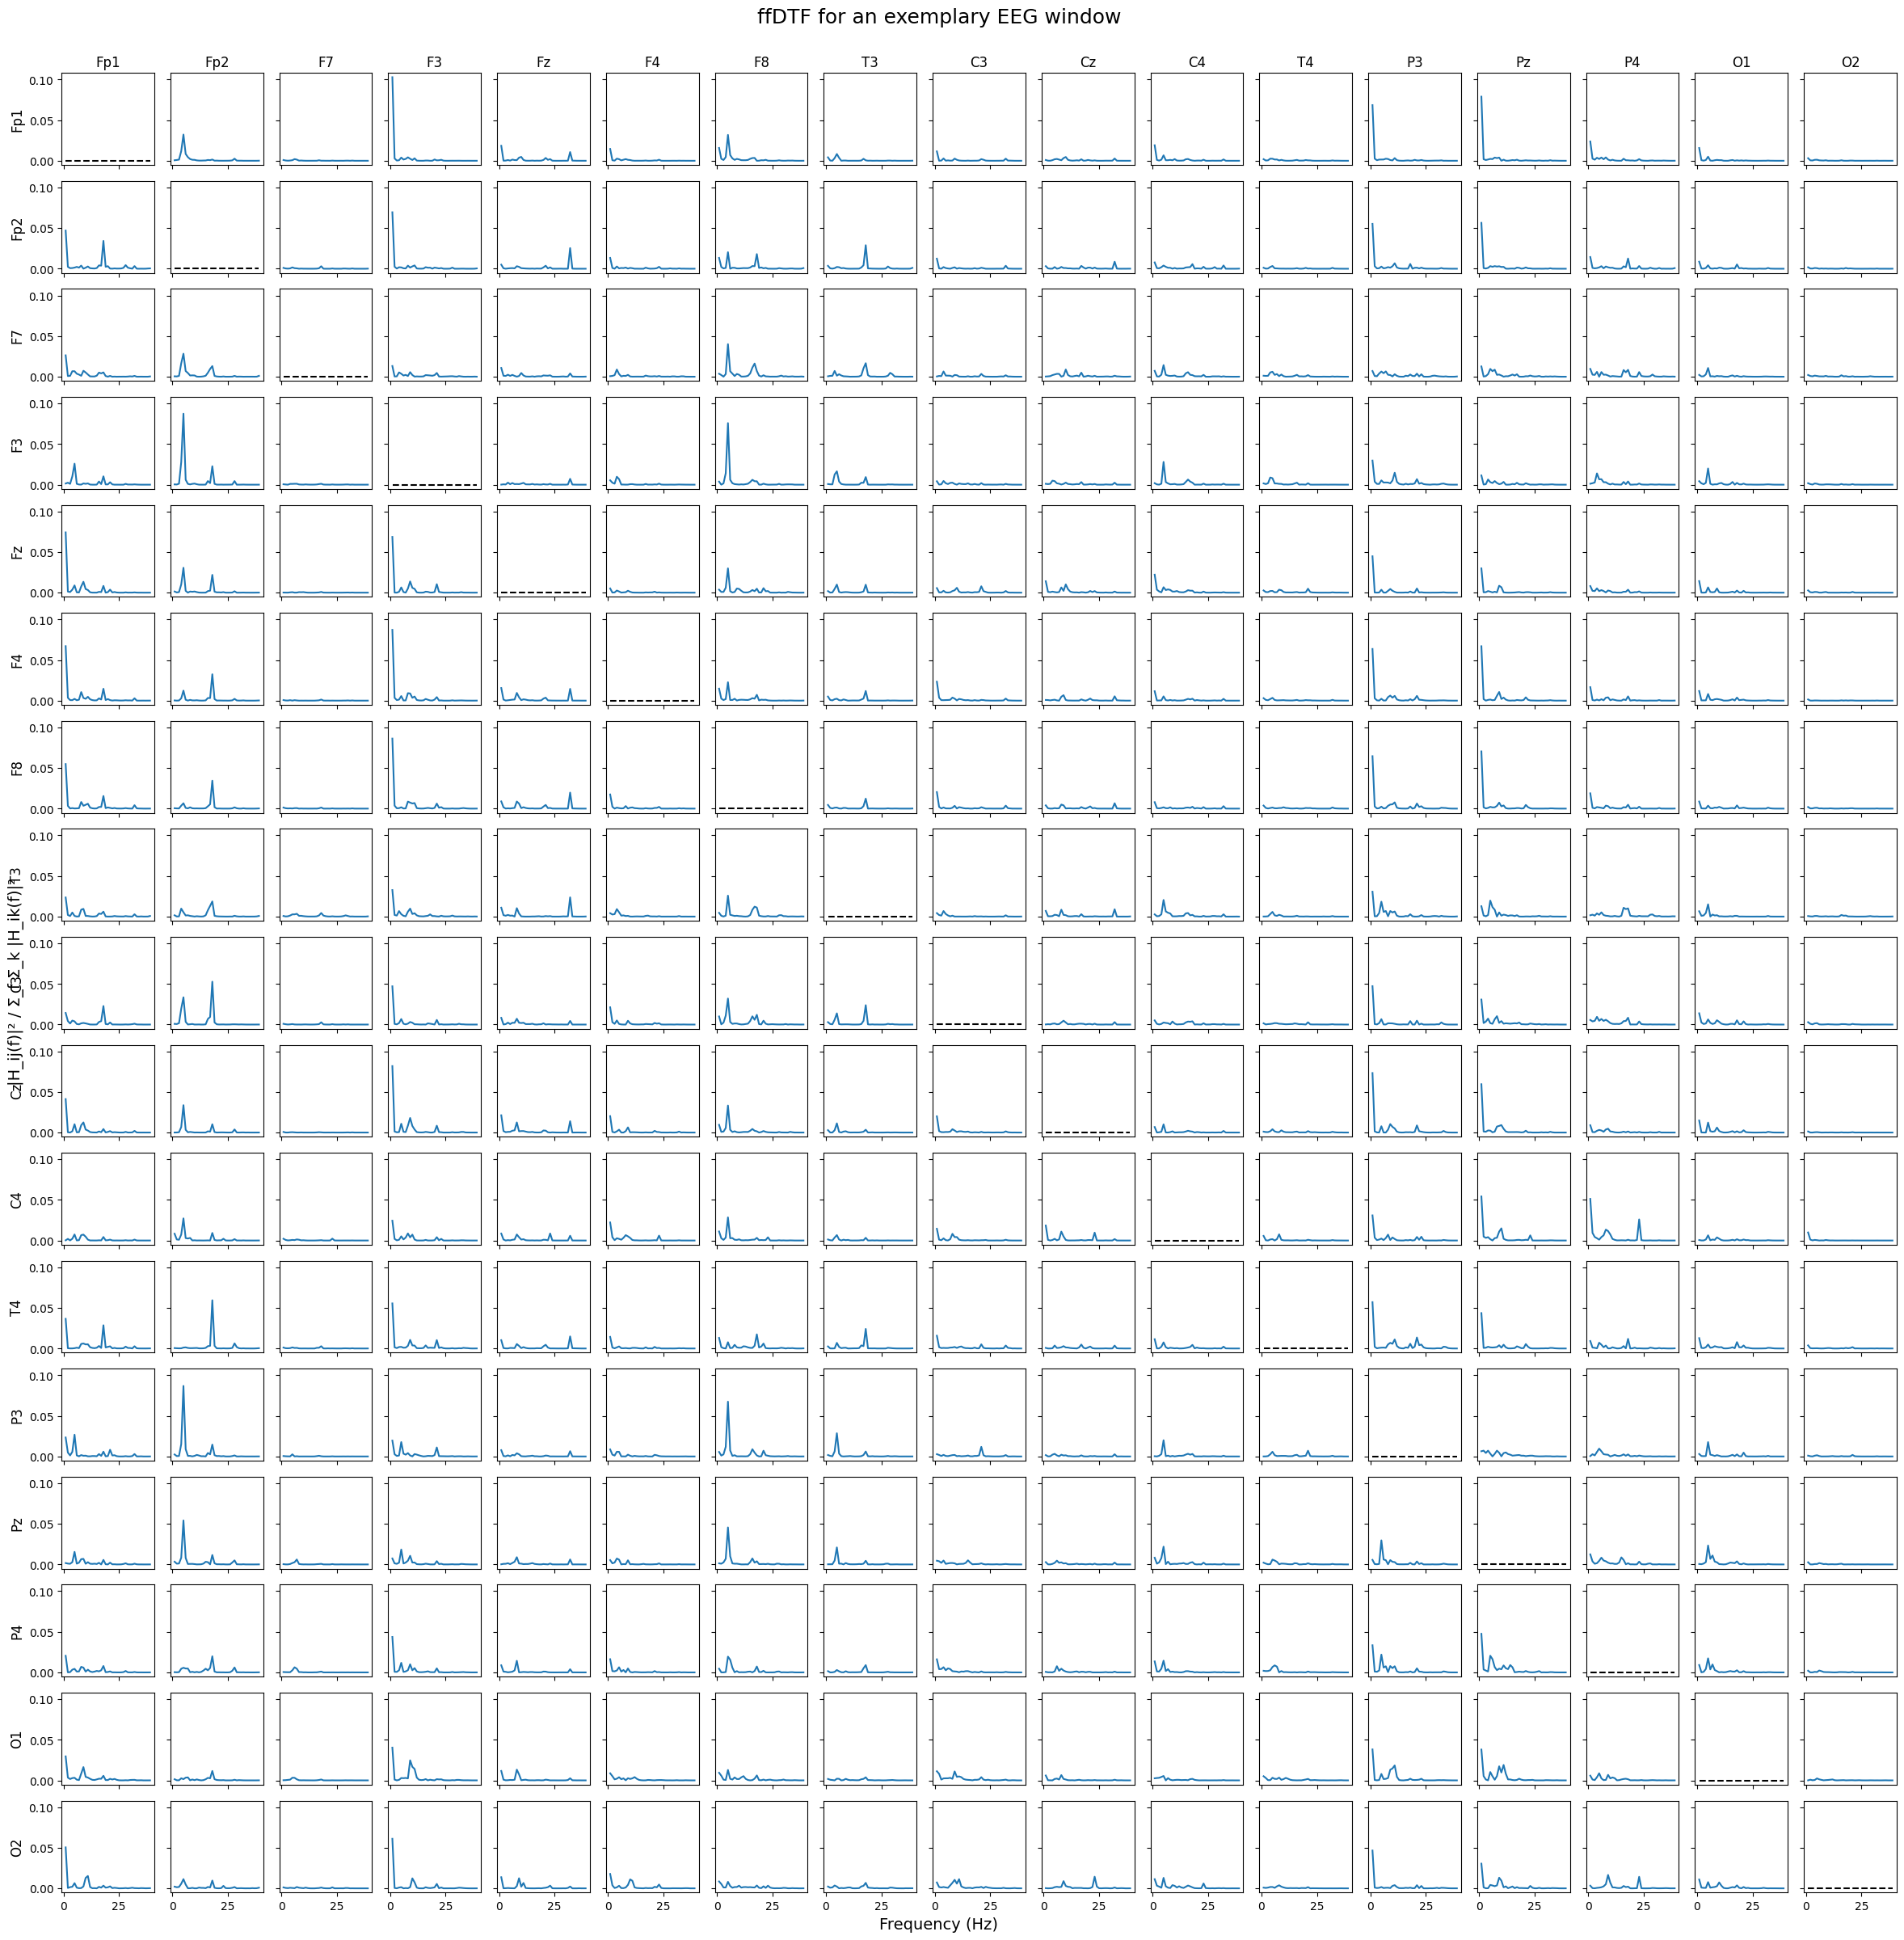

In [12]:
plot_all_flows(NDTF, ylabel = "|H|²", conn_name = 'NDTF')
plot_all_flows(ffDTF) #ylabel and name are set default to ffDTF

## create connectivity matrices aggregated over frequency bands

In [13]:
NDTF_bands = aggregate_bands(NDTF)
ffDTF_bands = aggregate_bands(ffDTF)

## visualize connectivity by bands

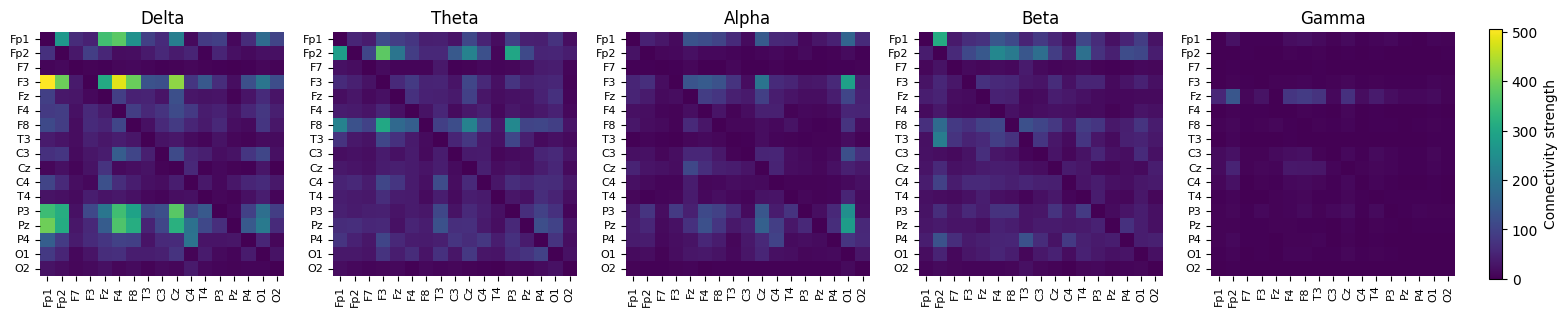

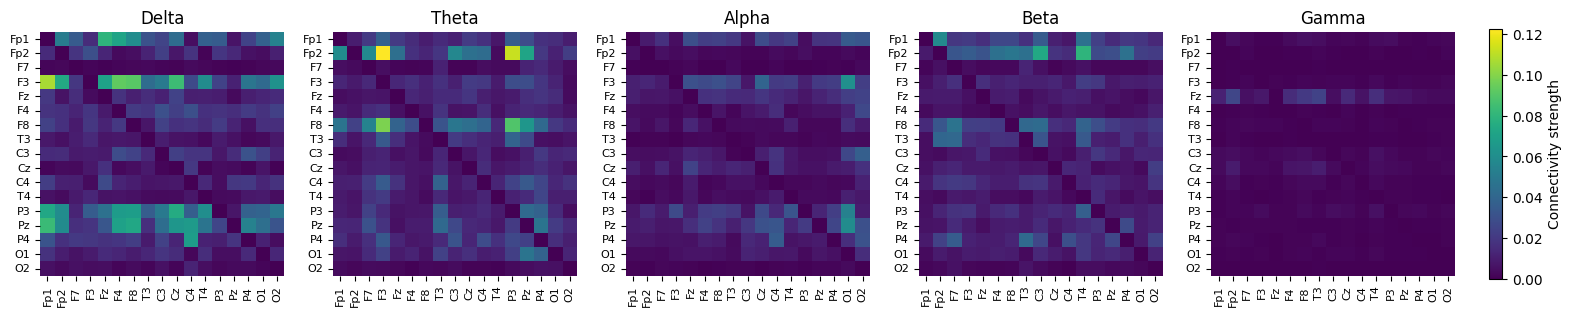

In [14]:
heatmap_bands(NDTF_bands)
heatmap_bands(ffDTF_bands)
plt.show()

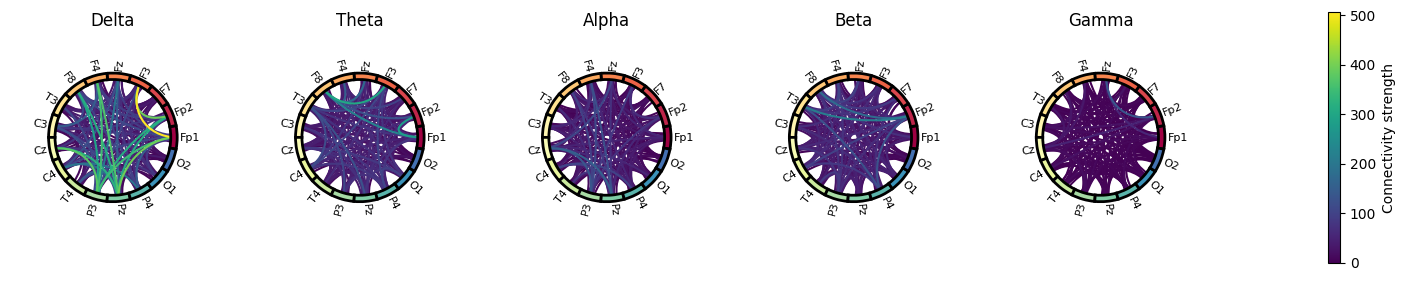

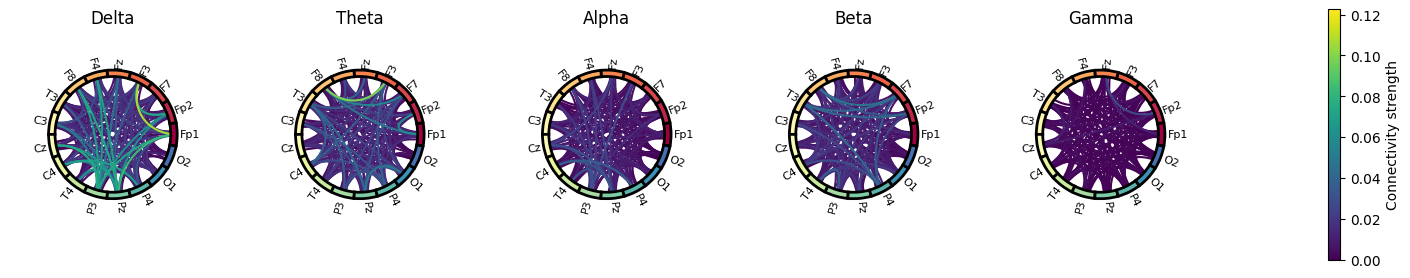

In [15]:
circle_bands(NDTF_bands)
circle_bands(ffDTF_bands)
plt.show()

## bands & graphs (visualize & create) with montage

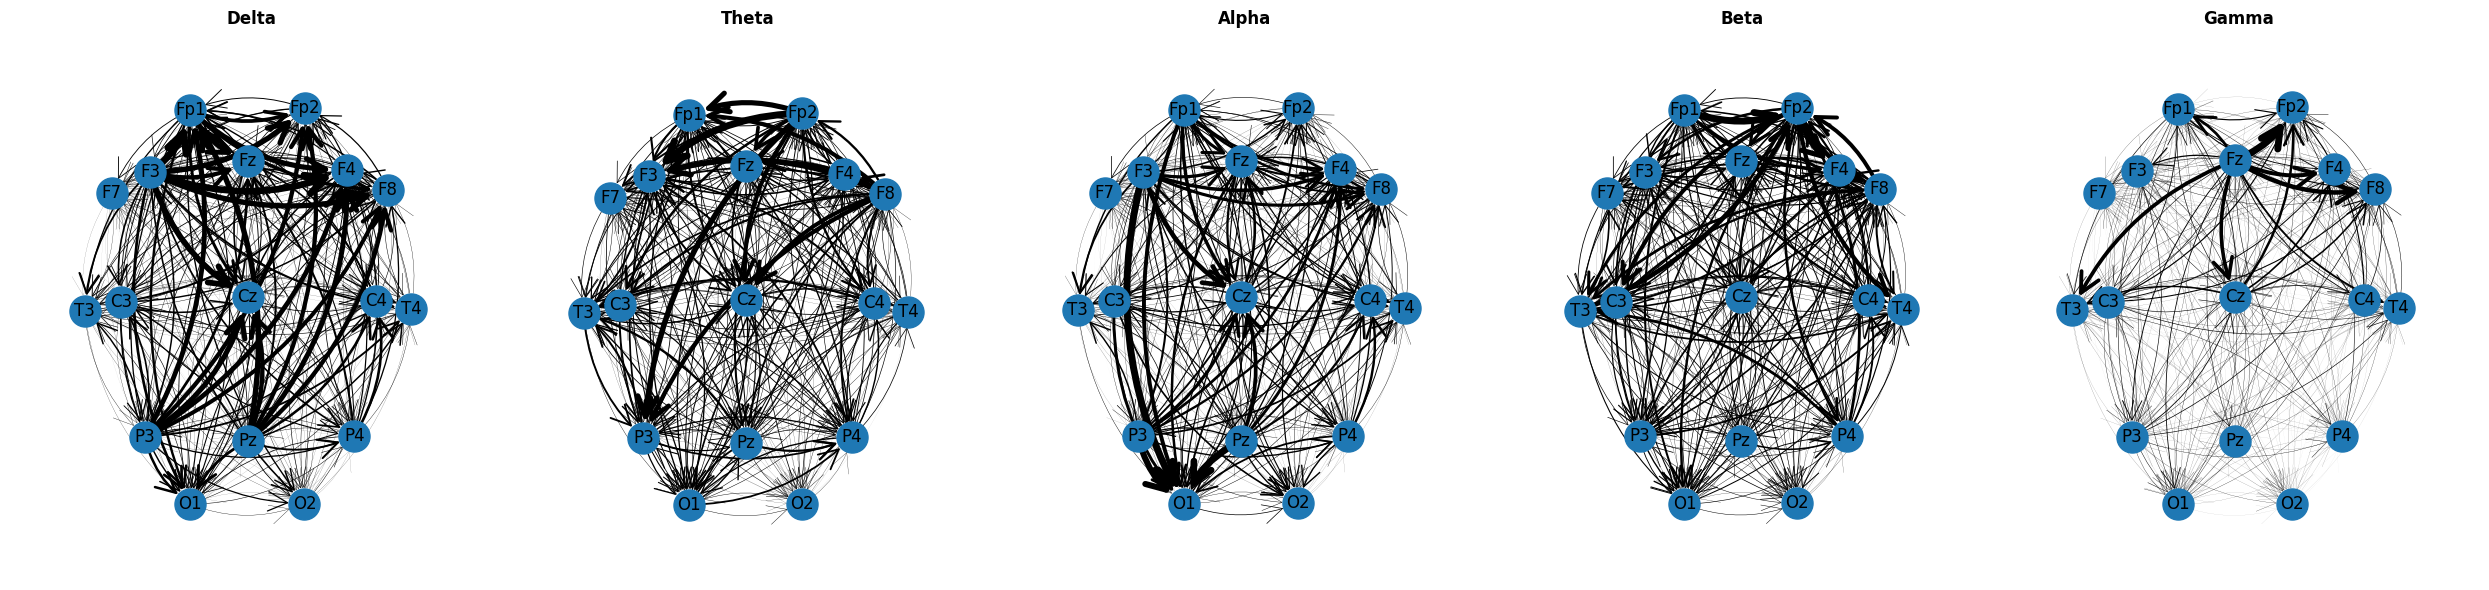

In [16]:
Gs_NDTF = graph_bands(NDTF_bands)
plt.show()

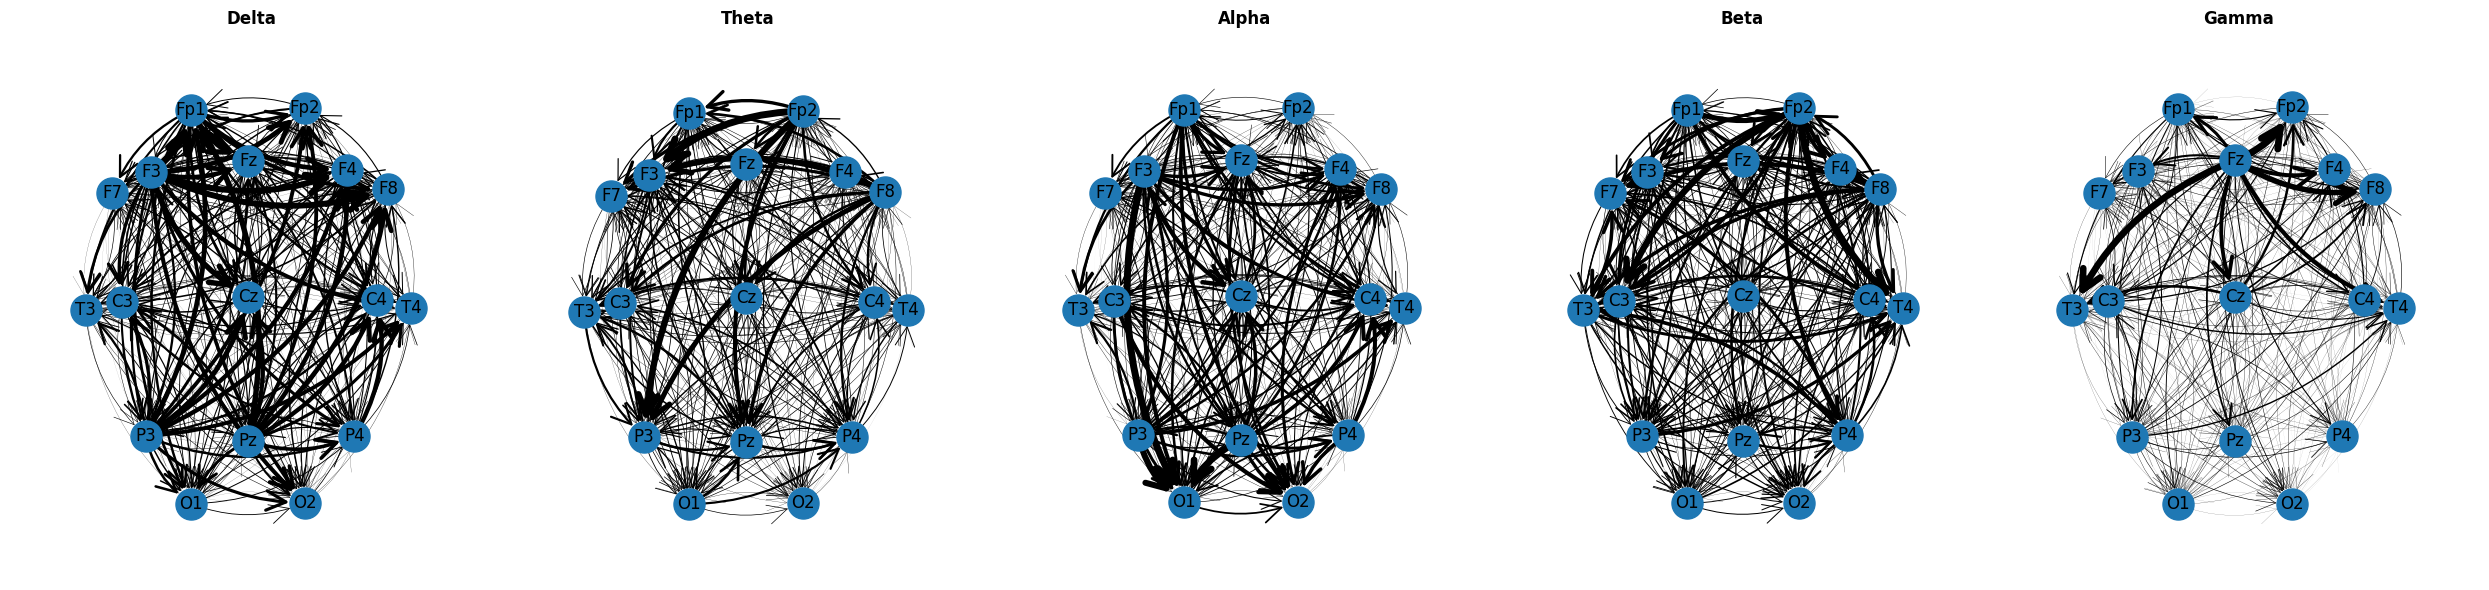

In [17]:
Gs_ffDTF = graph_bands(ffDTF_bands)
plt.show()

In [18]:
G_NDTF_orig_alpha = Gs_NDTF['Alpha']
G_NDTF_orig_alpha

## graphs with only the strongest connections

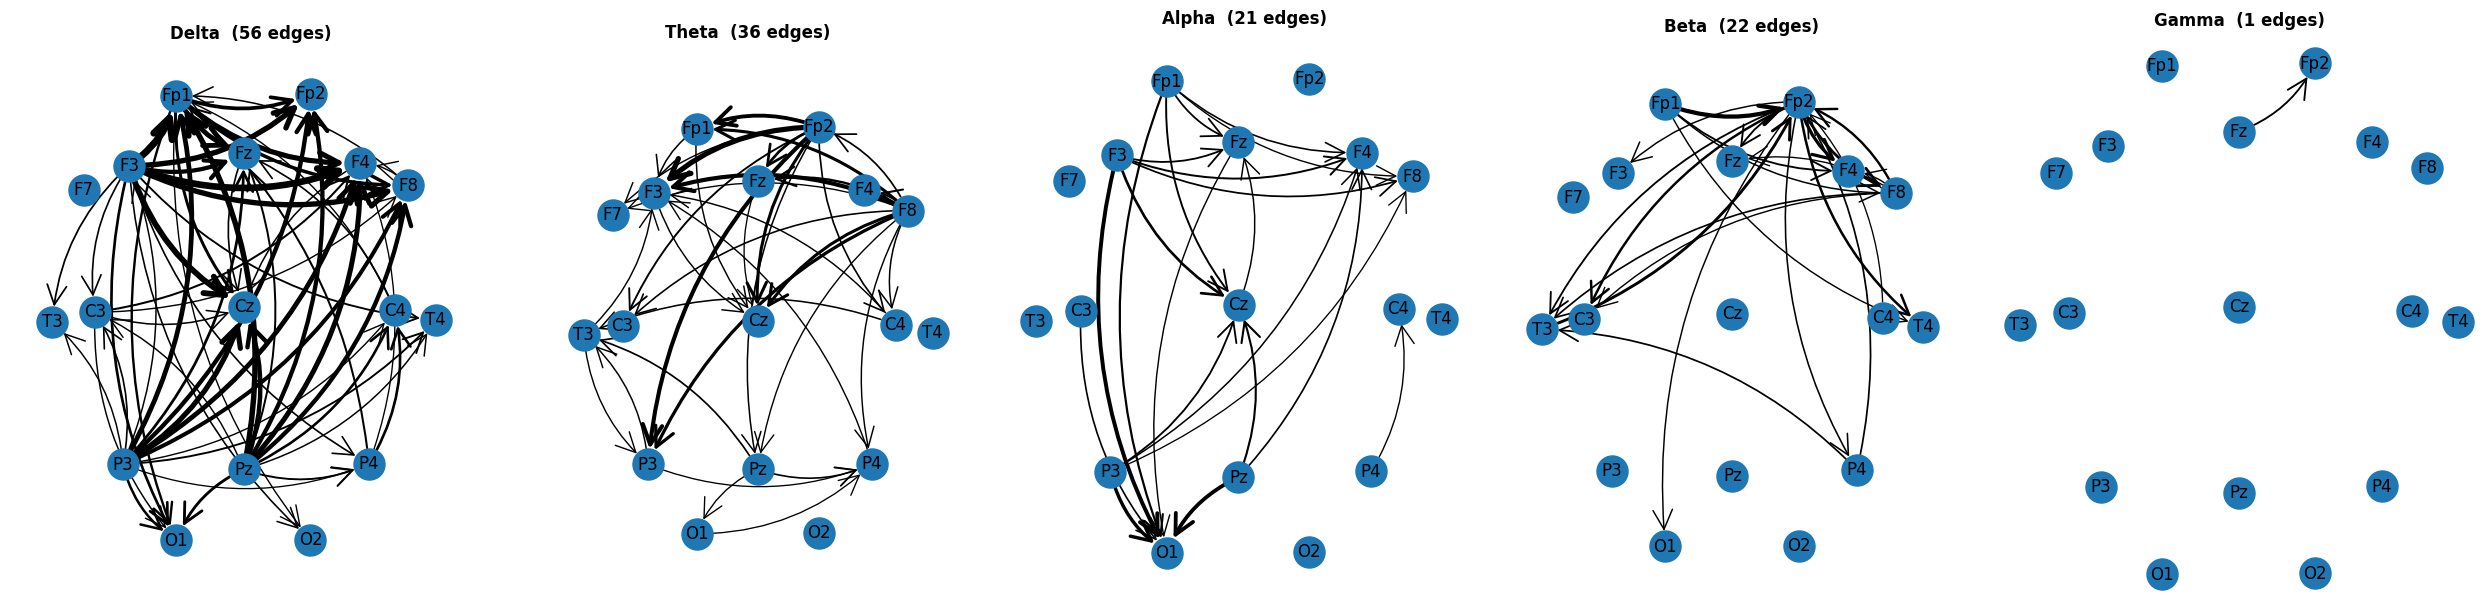

In [19]:
GsS_NDTF = graph_bands_sparse(NDTF_bands, mode = 'global')
plt.show()

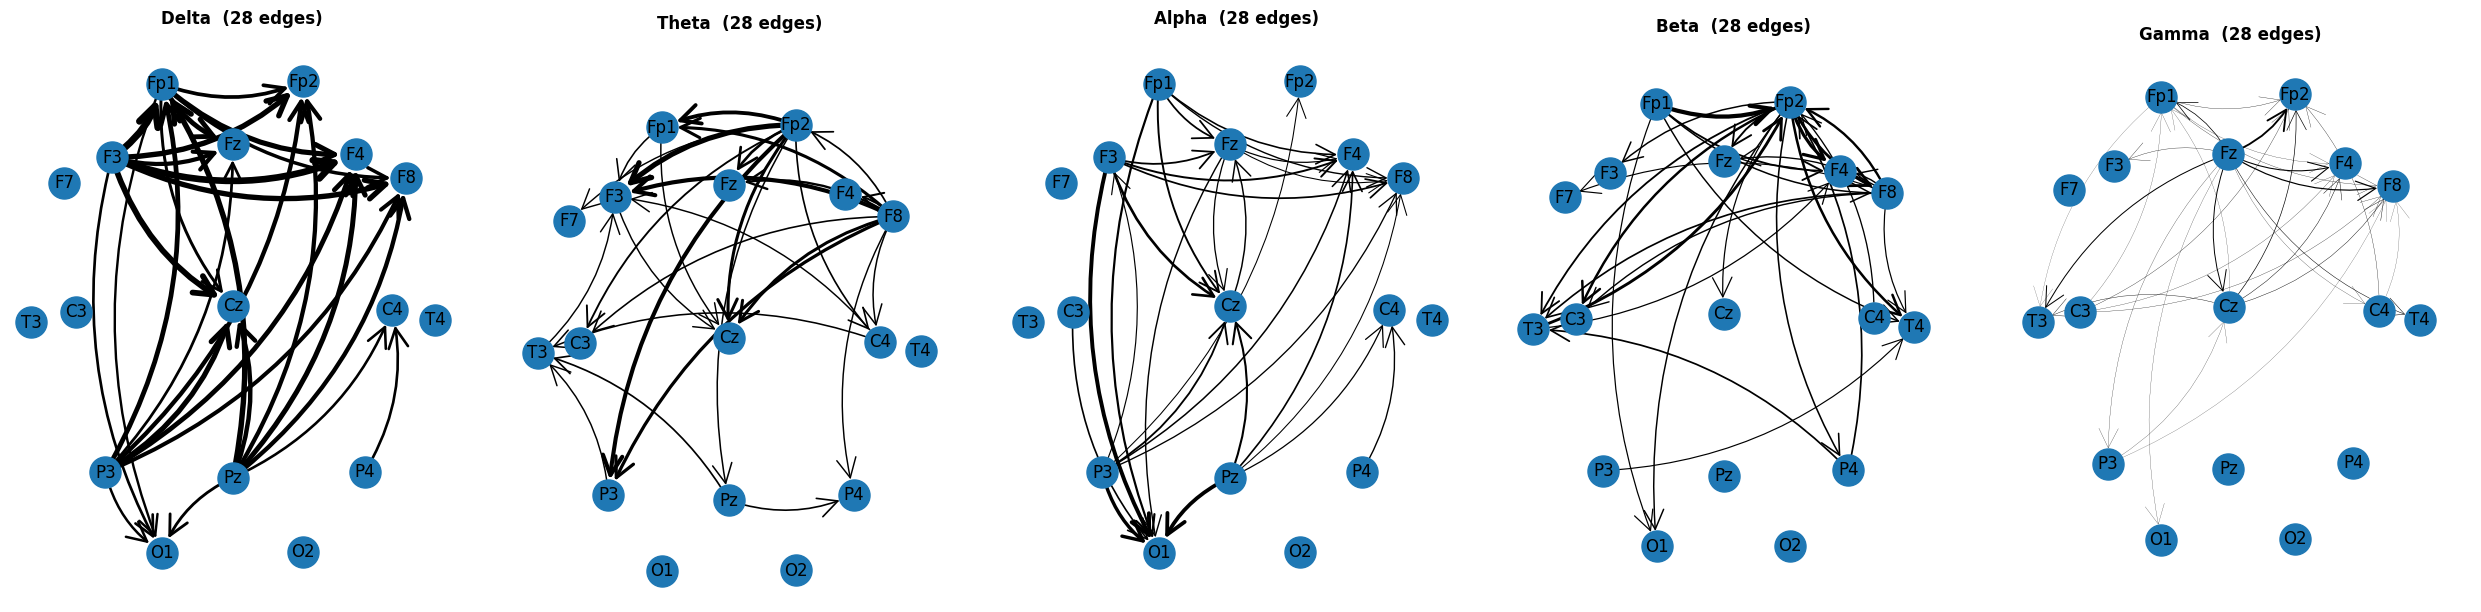

In [20]:
GsS_NDTF = graph_bands_sparse(NDTF_bands, mode = 'per_band')
plt.show()

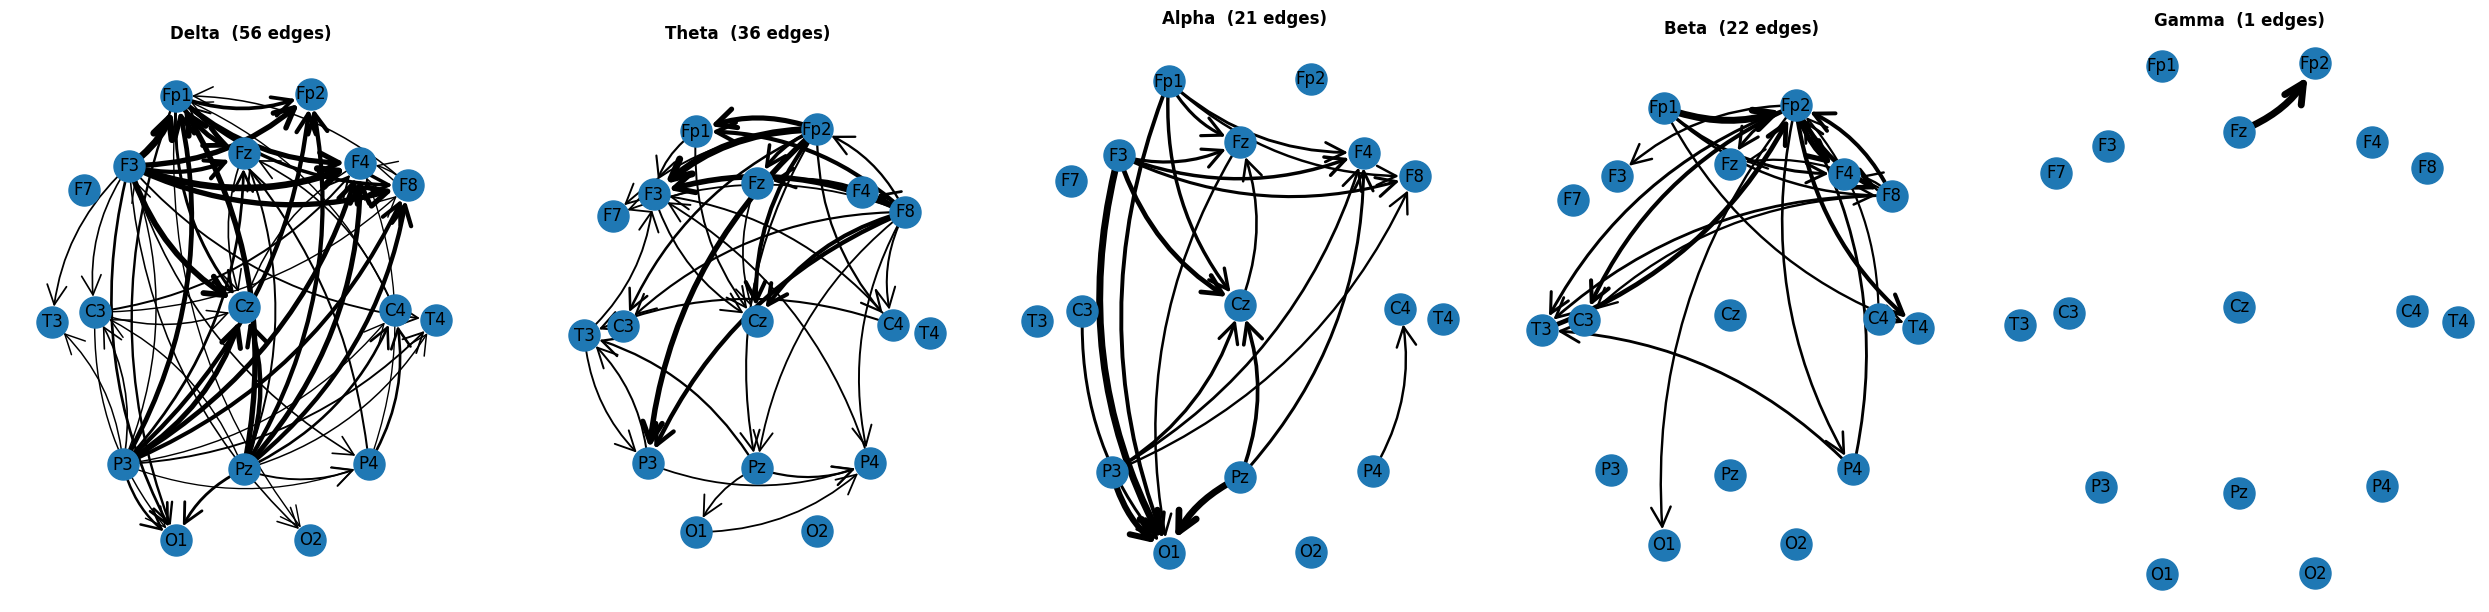

In [21]:
GsSB_NDTF = graph_bands_sparse(NDTF_bands, shared_scale = False)
plt.show()

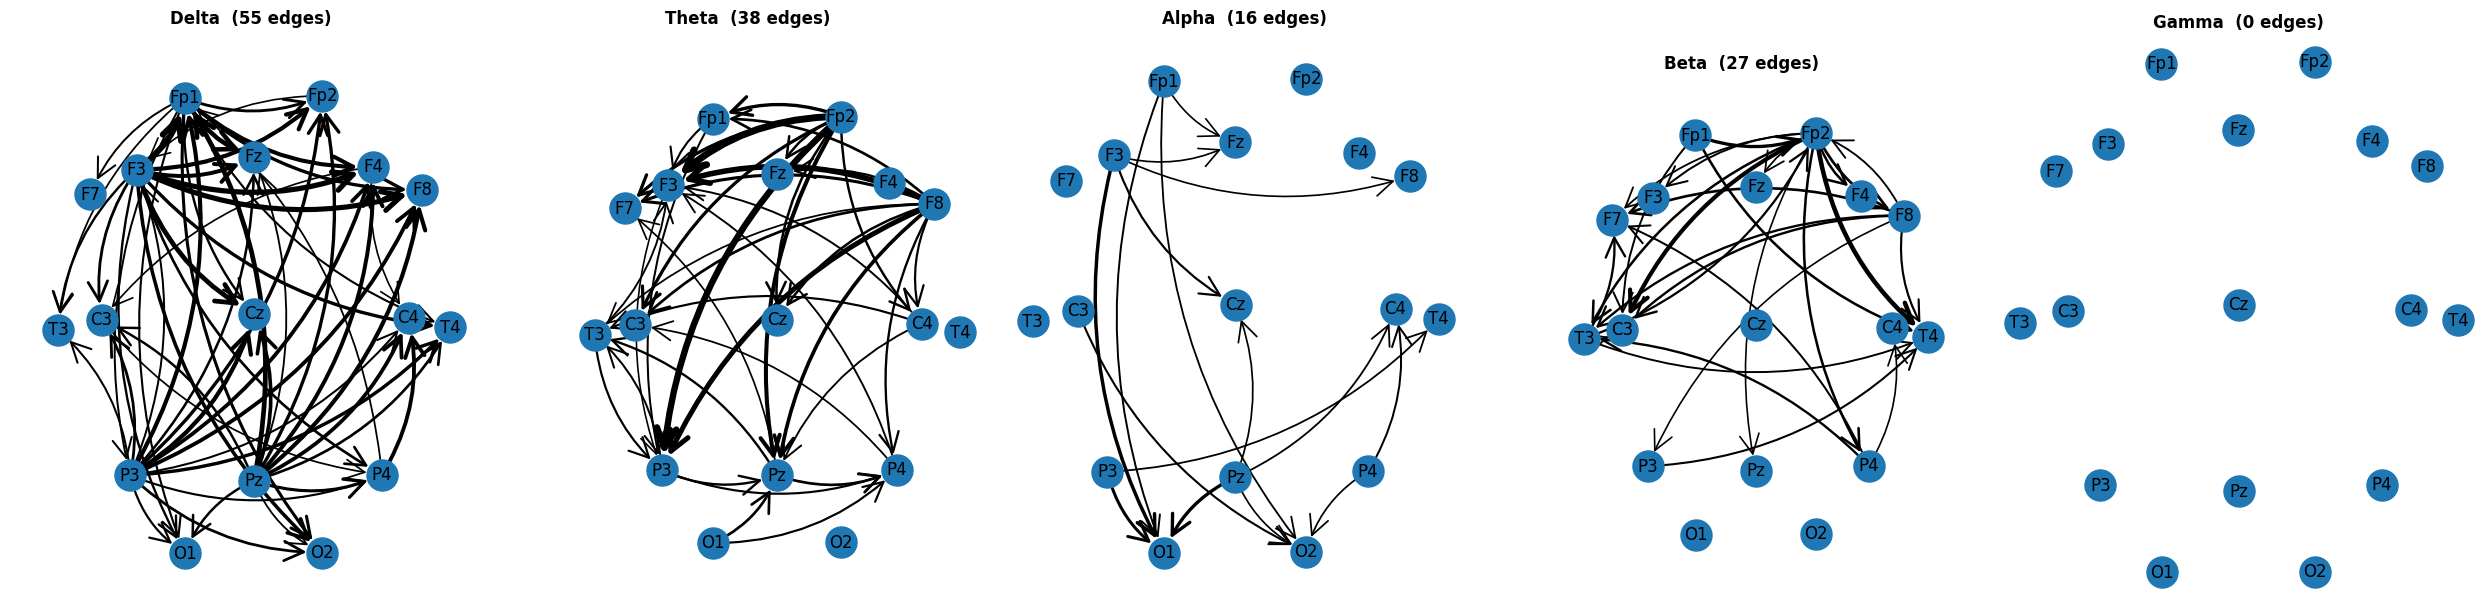

In [22]:
GsS_ffDTF = graph_bands_sparse(ffDTF_bands)
plt.show()

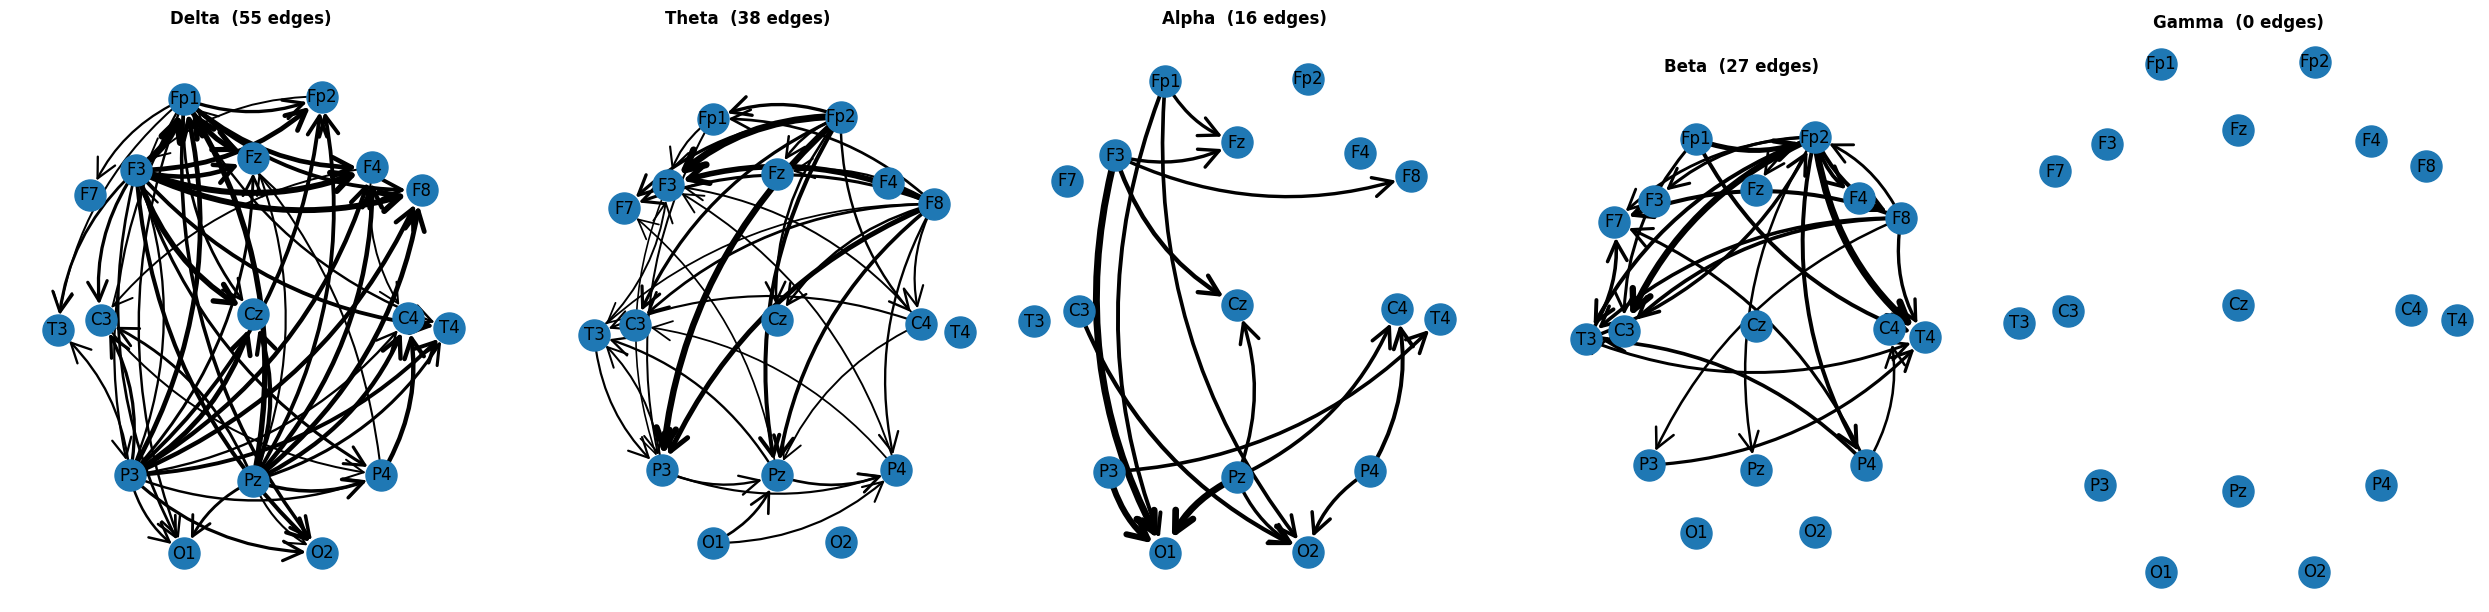

In [23]:
GsSB_ffDTF = graph_bands_sparse(ffDTF_bands, shared_scale = False)
plt.show()